In [1]:
# Dependencies
from typing  import Callable, TypeVar
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, cumulative_trapezoid


- Random Search

In [2]:
# 1. Taxonomy
# Random Search belongs to the fields of stochastic optimization and global optimization

# 2. Strategy
# The strategy is to randomly sample solutions from across the entire space using a unifrom distribution, in which each future 
# sample is independent of the samples that come before it. 

# 3. Implementation

problem_size: int = 1 # The problem size (the number of variables)
search_space: tuple[float, float] = (-10, 10) # The search space (the range of values for each variable)
num_iterations: int = 9 # The number of iterations (the number of random solutions to generate)

# 3.1. Pseudocode

# Below is presented the pseudocode of the random search algorithm before the implementation in Python.
# Input: num_iterations, search_space, cost
# Output: best
#1 best = Ø;
#2 foreach i in num_iterations do
#3     candidate_i = random_solution(problem_size, search_space);
#4     if best = Ø or cost(candidate_i) < cost(best) then
#5         best = candidate_i;
#6      end
#7 end
#8 return best;

In [3]:
# 3.2. Python Implementation

def random_solution(problem_size: int, search_space: tuple[float, float]) -> np.ndarray:
    low, high = search_space
    _random_solution = np.random.uniform(low, high, problem_size)
    return _random_solution

Cost = Callable[[np.ndarray], float]
cost: Cost = lambda x: float(np.sum((x - 3) ** 2)) # It's the cost function (the one we want to minimize)

def random_search(
        num_iterations: int,
        search_space: tuple[float, float],
        cost: Cost,
        problem_size: int = 1
        ) -> float | np.ndarray:
    if num_iterations < 1 or problem_size < 1:
        raise ValueError('num_iterations and problem_size must be positive')
    best = random_solution(problem_size, search_space)
    best_cost = cost(best)
    for _ in range(1, num_iterations):
        candidate = random_solution(problem_size, search_space)
        candidate_cost = cost(candidate)
        if candidate_cost < best_cost:
            best, best_cost = candidate, candidate_cost
    return best.item() if problem_size == 1 else best

random_search(num_iterations, search_space, cost)

3.239148995944621

In [4]:
# 3.3. Heuristics
# - Random Search is "minimal" in the sense that it only requires a candidate solution construction routine and a
    # candidate solution evaluation routine as well.
# - The worst case performance for Random Search for locating the optima is worse than an enumeration of the search domain
    # (since it's no memory, and can blindly resample the same values; on the contrary, checking one by one hasn't this problem)
# - Random Search can return a reasonable approximation of the optimal solution within a reasonable time, depending on dimensionality
    # (so it does not scale well; it's complexity is O(num_iterations * problem_size)).
# - Care must be taken to ensure that random candidate solution construction is unbiased.
# - The results of Random Search can be used to seed another search technique, like a local search technique (such as the Hill Climbing
    # algorithm) that can then be used to locate the best solution in its vicinity.

- Local Search (Stochastic Hill Climbing)

In [5]:
# 1. Taxonomy
# Stochastic Hill climbing belongs to the fields of stochastic optimization and local optimization, being an extension
# of deterministic Hill Climbing.

# 2. Strategy
# The strategy is iterate the process of randomly selecting a neighbor for a candidate solution, and only accept if it results
# in an improvement.

# 3. Pseudocode
# Input: num_iterations, problem_size
# Output: current
#1 current = random_solution(problem_size);
#2 foreach i in num_iterations do
#3     candidate_i = random_neighbor(current);
#4     if cost(candidate_i) < cost(current) then
#5         current = candidate_i;
#6      end
#7 end
#8 return current;

In [6]:
# 3. Python implementation of Stochastic Hill Climbing (for a minimization problem)

def random_neighbor(current: np.ndarray, search_space: tuple[float, float], step: float) -> np.ndarray:
    low, high = search_space
    move = np.random.uniform(-step, step, size = current.shape)
    return np.clip(current + move, low, high) 

def local_search(
        num_iterations: int, 
        search_space: tuple[float, float], 
        cost: Cost,
        problem_size: int = 1,
        step: float = .5
        ) -> float | np.ndarray:
    
    if problem_size < 1:
        raise ValueError('problem_size must be positive')
    low, high = search_space
    current: np.ndarray = np.random.uniform(low, high, problem_size)
    current_cost = cost(current)
    for _ in range(num_iterations):
        candidate: np.ndarray = random_neighbor(current, search_space, step)
        candidate_cost = cost(candidate)
        if candidate_cost <= current_cost:
            current, current_cost = candidate, candidate_cost
    return current.item() if problem_size == 1 else current

local_search(10, (-10, 10), cost)

1.5280094840927565

In [7]:
# 4. Heuristics
# - Stochastic Hill Climbing was designed for discrete domains with explicit neighbors, such as combinatorial optimization, rather
# than for continuous function optimization.
# - It can be used on continuous domains if a step size defines what a neighbor is.
# - It is a local search technique, not a global one, and can be used to refine a result after a global search has run.
# - Although the process is stochastic, it can still get stuck in local optima.
# - Neighbors with better or equal cost should be accepted, so the search can move across plateaus in the response surface.
# - The algorithm can be restarted and repeated several times after it converges to give a better result (Multiple Restart Hill Climbing).
# - It can be applied to several candidate solutions at once, running multiple runs concurrently (Parallel Hill Climbing).

- Simulated Annealing

In [8]:
# Setup and acceptance probability
State = TypeVar('State')
Schedule = Callable[[int], float]
Successor = Callable[[State], State]

def acceptance_probability(E0: float, Ef: float, T: float) -> float:
    dE = Ef - E0
    if dE <= 0:
        return 1
    else:
        return np.exp(-dE/T)

In [9]:
# Cooling Schedule
T_min = .01
## Geometric Cooling Schedule
def geometric_cooling_schedule(T_0: float, alpha: float = .95, T_min: float = T_min) -> Schedule:
    def schedule(k: int):
        T = T_0 * alpha ** (k - 1)
        return T if T > T_min else .0 # It's vital to have T_min as the cutoff (the smaller the longer we'll get to converge)
    return schedule                   # the main idea is that, since we'll not want to start with 0, any positive number times
                                      # a positive number is always positive, so T will shring "forever", but not exactly to 0.
## Pairing Cooling Schedule with Perturbation
def log_cooling_schedule(T_0: float, T_min: float = T_min) -> Schedule:
    def schedule(k: int) -> float:
        T = T_0 / np.log(k + 1)      
        return T if T > T_min else .0
    return schedule

def proportional_cooling_schedule(T_0: float, T_min: float = T_min) -> Schedule: # Fast Annealing
    def schedule(k: int) -> float:
        T = T_0 / k          
        return T if T > T_min else .0
    return schedule

In [10]:
# Setting up the perturbation logic

def create_local_perturbation(kind: str = 'gauss') -> Successor:
    '''
    kind allows us to define the nature of local perturbation, that is make random changes in the vicinity
    of the previous value to define the current.
    '''
    def successor(x: int | np.ndarray) -> float | np.ndarray:
        if kind.lower() == 'gauss':
            return x + np.random.normal(0, 1)
        elif kind.lower() == 'cauchy':
            return x + np.random.standard_cauchy()
        elif kind.lower() == 'bitflip':
            candidate = x.copy()
            i = np.random.randint(candidate.size)
            candidate[i] = 1 - candidate[i]
            return candidate
        else:
            return x + np.random.choice([-1, 1])
    return successor

In [11]:
# Implementation of Simulated Annealing

def simulated_annealing(
        initial_state: State,
        schedule: Schedule,
        cost: Callable[[State], float],
        successor: Successor,
        verbose: bool = True
) -> tuple[State, float]:    
    previous = initial_state 
    previous_cost = cost(previous)
    best, best_cost = previous, previous_cost

    t = 1
    while True:
        T = schedule(t)
        if T == .0:
            if verbose:
                print('Converged after ', t - 1, 'iterations')
            return best, best_cost
        
        current = successor(previous)
        current_cost = cost(current)
        
        p = acceptance_probability(previous_cost, current_cost, T)
        if np.random.random() < p:
            previous, previous_cost = current, current_cost
        if current_cost < best_cost:
            best, best_cost = current, current_cost
        t += 1

In [12]:
# Instantiating for T_0 = 5 and -5 as initial_state

schedule = proportional_cooling_schedule(5)
successor = create_local_perturbation('cauchY')
simulated_annealing(-5, schedule, cost, successor)

Converged after  499 iterations


(2.991856478385039, 6.631694429333723e-05)

                                 Simulated Annealing Applied to the Knapsack Problem

In [13]:
# Setting up the problem

knapsack_capacity: int = 23 # kg (I'm taking TAP max free weight limit for checked bag in Economy Class)
n_items: int = 79 # Selecting initially 120 items to carry to Lisbon
value_arr: np.ndarray = np.random.uniform(1, 50, n_items) # The minimum and maximum value associated with the items I'm carrying in Euros
weight_arr: np.ndarray = np.random.uniform(.01, .8, n_items) # The minimum and maximum weight of the items I'm plannig to carry in kg
overweight_fee: int = 165 # Euros (the fixed overweight fee, not by kg TAP applies for Luanda-Lisbon) 
stuff = pd.DataFrame({'value': value_arr, 'weight': weight_arr})

def knapsack_cost(state) -> float:
    V, W = tuple([ state @ stuff[i] for i in stuff.columns])
    overweight: bool = (W - knapsack_capacity > 0)
    return -V + overweight_fee if overweight else -V

In [14]:
# Instantiating for T_0 = 5

schedule = proportional_cooling_schedule(5)
successor = create_local_perturbation('bitflip')
initial_state = np.random.randint(0, 2, size = n_items)
optimal_items_comb, best_net_value = simulated_annealing(initial_state, schedule, knapsack_cost, successor)
items_to_carry = stuff.iloc[optimal_items_comb == 1]

print(f'items value: € {round(- best_net_value, 2)} ', f'\nitems to carry: {len(items_to_carry)}')

Converged after  499 iterations
items value: € 1418.92  
items to carry: 55


                                    Fed-Batch Fermenter Feed Trajectory

###### Disclaimer: illustartions generated by Claude :]

- Fermentation Strategies

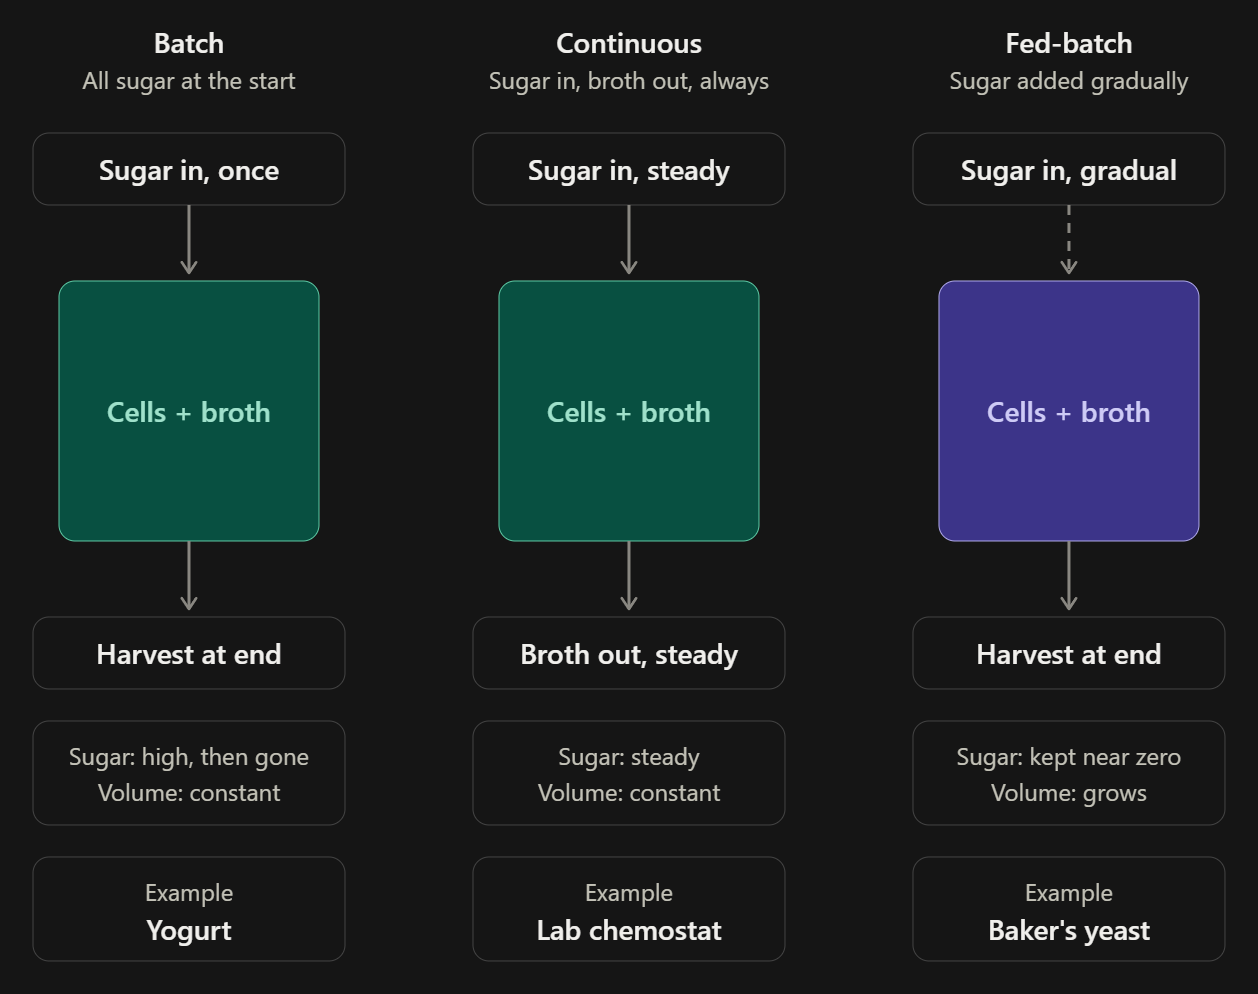

- Process Examples

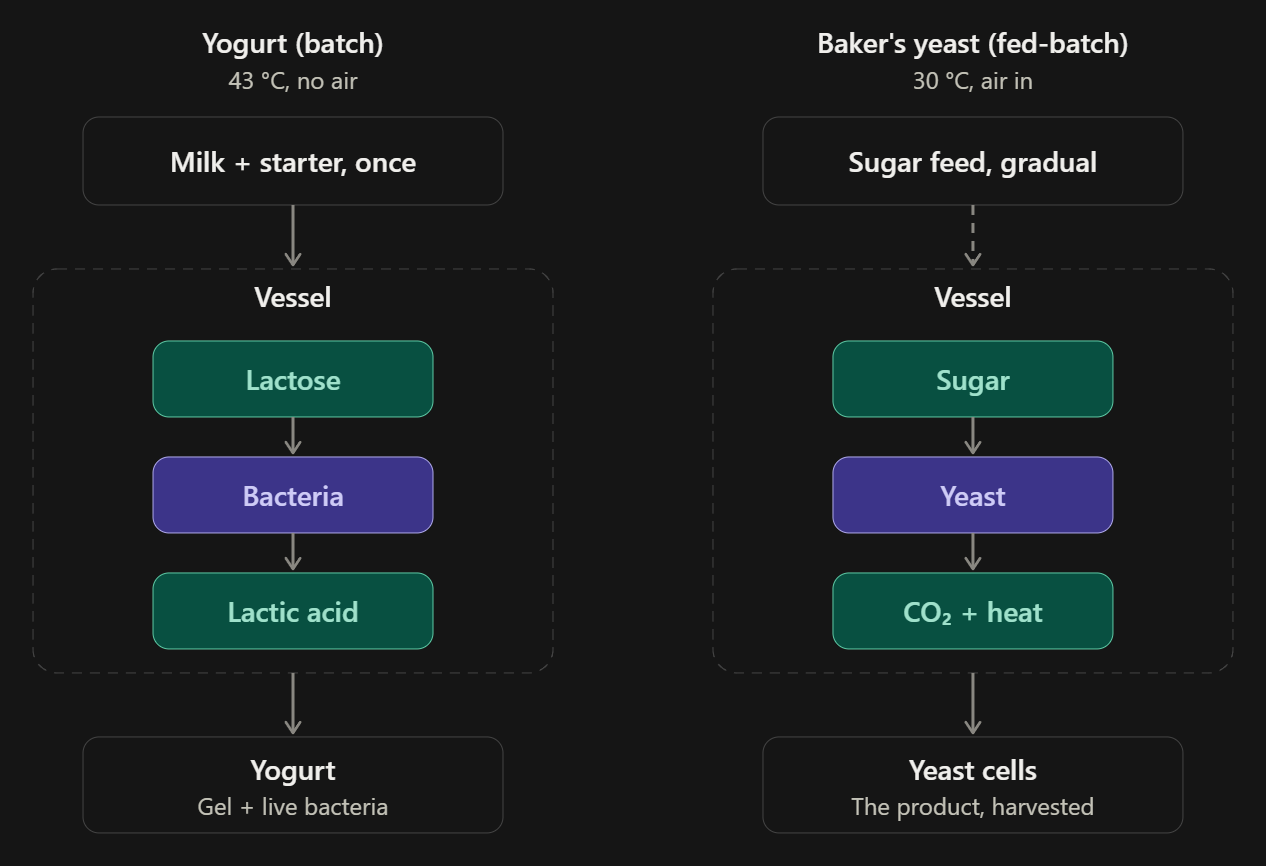

- Fed-Batch's Phases

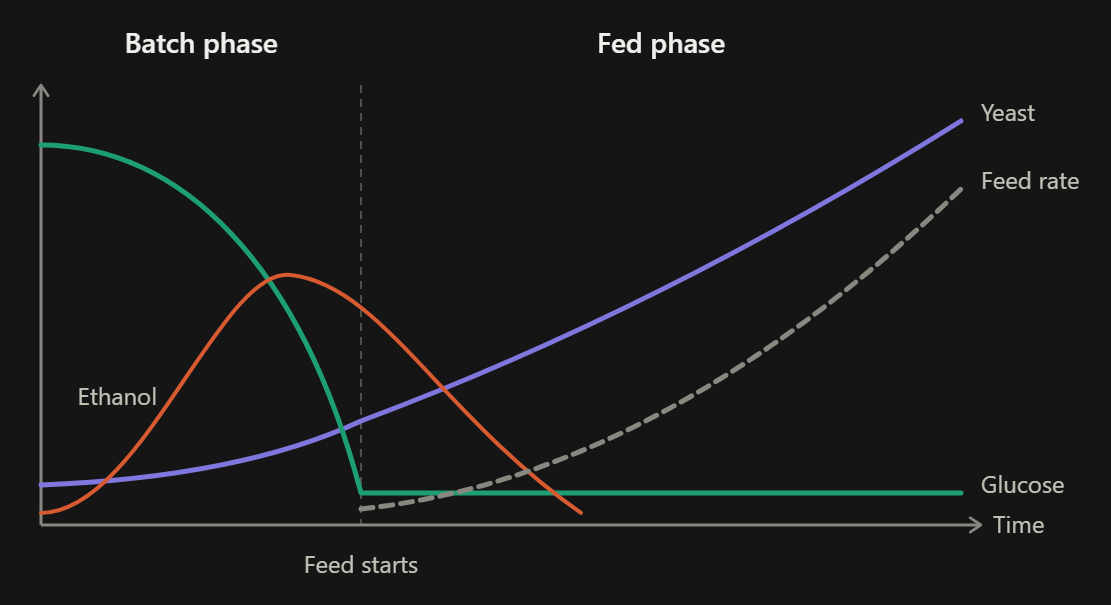

- Feed Profiles

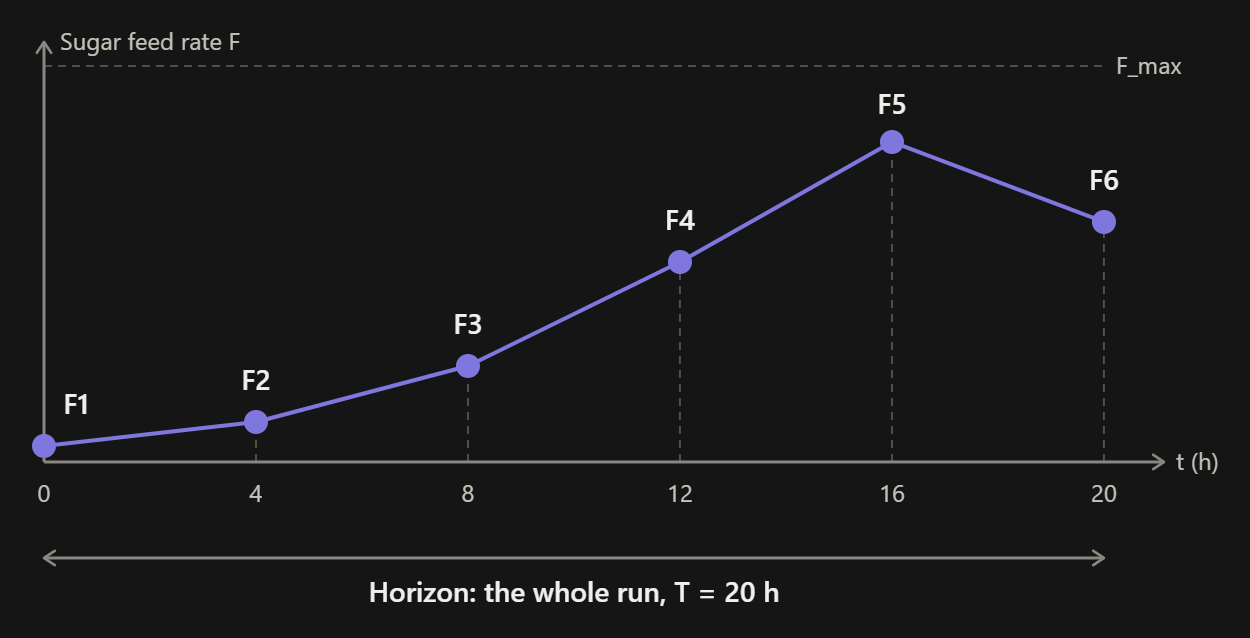

In [15]:
# Python implementation 

## kinetics (the cells)
μ_max: float = .5               # [1/h]  growth-rate ceiling; the real mu(S) is always below it
Ks: float = 1.                  # [g/L]  low-sugar half-saturation constant; μ ≈ μ_max/2 when inhibition is weak
Ki: float = 100.                # [g/L]  inhibition constant; smaller = sugar inhibits sooner
Y_xs: float = .5                # [g/g]  grams of cells made per gram of sugar consumed
                                 # At μ_max, S is sqrt(ks * ki) [dmu(s)/ds]

## Feed 
S_in   = 300.                    # [g/L]  substrate (sugar) concentration of the feed solution

## Initial state
V0 = 5.                          # [L]    starting liquid volume
X0 = 2.                          # [g/L]  starting cell concentration
S0 = 20.                         # [g/L]  starting sugar concentration

## Horizon and feed nodes
T = 20.                          # [h] run length
N = 6                            # [-] number of feed nodes
t_nodes = np.linspace(0, T, N)   # [h] node times: 0, 4, 8, 12, 16, 20

## Limits
V_max = 10.       # [L]    maximum working volume
S_max = 30.       # [g/L]  maximum allowed sugar concentration (substrate operational limit)
F_max = 1.        # [L/h]  maximum pump feed rate

# Feed Profile F(t) from the nodes values
def F(t, F_nodes):
    f = np.interp(t, t_nodes, F_nodes)
    return np.clip(f, 0., F_max)        # 0 <= F <= F_max

# Haldane Growth Rate
def μ(S): # Haldane Kinetics
    S = np.maximum(S, .0)
    return μ_max * S / (Ks + S + S**2 / Ki)

# Dynamics (ODEs)
def rhs(t, state, F_nodes):
    X, S, V = state
    f  = F(t, F_nodes)                             # [L/h]  feed now
    μ_s  =  μ(S)                                   # [1/h]  growth rate now
    dX =  μ_s * X - (f / V) * X                    # growth minus dilution by feed
    dS = -(μ_s / Y_xs) * X + (f / V) * (S_in - S)  # consumption + incoming sugar - dilution
    dV = f                                         # nothing leaves the tank
    return [dX, dS, dV]

def run(F_nodes, n_points = 2001): # Runs the tank for T hours
    t_eval = np.linspace(0, T, n_points)
    sol = solve_ivp(
        rhs, (0, T), [X0, S0, V0], args = (F_nodes,),
        t_eval = t_eval, method = 'LSODA', rtol = 1e-8, atol = 1e-10
        )
    X, S, V = sol.y
    assert (t_eval == sol.t).all()
    return sol.t, X, S, V

def FBF(F_nodes: np.ndarray) -> dict: # Fed-Batch Fermentation
    t, X, S, V = run(F_nodes)
    f = np.array([F(tt, F_nodes) for tt in t])
    sugar_fed = S_in * cumulative_trapezoid(f, t, initial = 0)[-1]   # [g] total sugar pumped in
    out = dict(
        X_T       = X[-1],             # [g/L] final cell concentration
        XV_T      = X[-1] * V[-1],     # [g]   final total biomass
        S_peak    = S.max(),           # [g/L] highest sugar reached
        V_T       = V[-1],             # [L]   final volume
        sugar_fed = sugar_fed,         # [g]   cost side
        viol_S    = S.max() - S_max,   # [g/L] > 0 means sugar limit broken
        viol_V    = V[-1] - V_max,   # [L]   > 0 means volume limit broken
    )
    out['feasible'] = (out['viol_S'] <= 0) and (out['viol_V'] <= 0)
    return out

start = np.random.uniform(.0, .1)
stop = np.random.uniform(.3, .5)
F_nodes: np.ndarray = np.linspace(start, stop, N)
results: dict = FBF(F_nodes)
round(results.get('X_T'), 2) # X(T) [g/L]

69.12

Simulated Annealing Applied to the Fed-Batch Fermenter

In [16]:
# Maximize final biomass concentration X(T) subject to the process limits
def X_T(F_nodes: np.ndarray) -> float:
    metrics: dict = FBF(F_nodes)
    feasible: bool = metrics['feasible']
    return -metrics['X_T'] if feasible else np.inf

def feed_successor(
        F_nodes: np.ndarray, 
        successor: Successor = create_local_perturbation('bitflip')
        ) -> np.ndarray:
    _successor = successor(F_nodes)
    _successor = np.clip(_successor + np.random.normal(.0, .1), .0, F_max)
    return _successor

best_F_nodes, best_cost = simulated_annealing(F_nodes, schedule, X_T, feed_successor)
best_metrics = FBF(best_F_nodes)
print('Best X(T) [g/L]:', round(best_metrics['X_T'], 2))

Converged after  499 iterations
Best X(T) [g/L]: 80.69


In [17]:
# A function for evaluating FBF across the search methods seen so far (RS, LS, and SA)

def evaluate(n_runs: int = 50, num_iterations: int = 25) -> None:
    if n_runs < 1 or num_iterations < 1:
        raise ValueError('n_runs and num_iterations must be positive')

    X_Ts: dict[str, list[float]] = {
        'Random Search': [],
        'Local Search': [],
        'Simulated Annealing': [],
    }
    search_space: tuple[float, float] = (.0, F_max)
    _T0 = T_min * (num_iterations + .5)
    schedule = proportional_cooling_schedule(_T0)

    for _ in range(n_runs):
        solvers = {
            'Random Search': lambda: random_search(
                num_iterations, search_space, X_T, problem_size = N
            ),
            'Local Search': lambda: local_search(
                num_iterations, search_space, X_T, problem_size = N, step = .1
            ),
            'Simulated Annealing': lambda: simulated_annealing(
                F_nodes, schedule, X_T, feed_successor, verbose = False
            )[0],
        }
        for name, solve in solvers.items():
            candidate = solve()
            metrics = FBF(candidate)
            X_Ts[name].append(metrics['X_T'])

    results = pd.DataFrame(X_Ts).round(2)
    if results.notna().sum().sum() == 0:
        raise RuntimeError('No feasible feed profile found; increase the iteration or run count')

    ax = results.plot(kind = 'box')
    ax.set_ylabel('Final biomass concentration X(T) [g/L]')
    ax.set_title(f'Optimizer Comparison ({n_runs} runs, {num_iterations} iterations)')
    plt.tight_layout()
    plt.show()

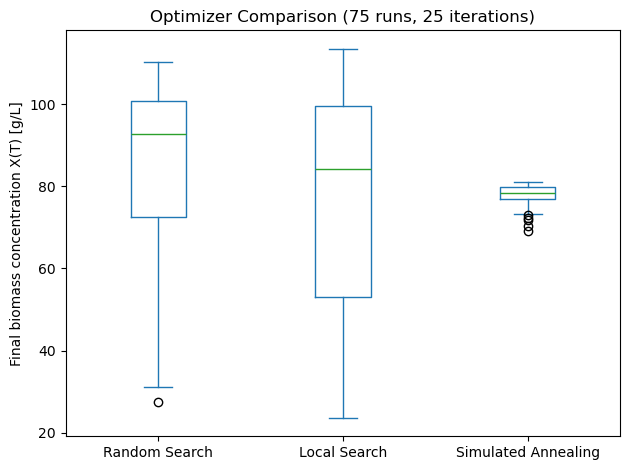

In [18]:
# Evaluating results for 75 runs

evaluate(75)